<a href="https://colab.research.google.com/github/praveen24sriv/Deepfake-video-detection-system/blob/feat%2Fml-pipeline/ml_pipeline/DeepGuard_Training_run_log.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DeepGuard — Spatiotemporal Deepfake Detector (Training)
**Model:** EfficientNet-B0 per frame (spatial) → BiLSTM across 16 frames (temporal) → video score + per-frame scores.
**Data:** FaceForensics++ C40 face crops from `FFpp_c40_Preprocessing.ipynb` (official video-level splits).

Outputs (saved to `MyDrive/DeepGuard_runs/<RUN_NAME>/`):
- `deepguard_v1.pt` + `deepguard.py` → drop-in model for the backend
- `results.csv`, `training_curves.png`, `roc_curves.png`, `confusion_matrix.png`, `per_method.png`, `gradcam_examples.png`

> Runtime → Change runtime type → **T4 GPU**. Training ≈ 2–3 h. A checkpoint is saved every epoch: after a disconnect just **Run all** again and it resumes.

In [ ]:
# 1. Setup
from google.colab import drive
drive.mount('/content/drive')
!pip install -q facenet-pytorch --no-deps   # only needed for the end-to-end test in the last section

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Shared module
`deepguard.py` holds preprocessing, the model, Grad-CAM and the predictor. The **same file** goes to the backend, so training and the app can never drift apart.

In [ ]:
%%writefile deepguard.py
"""
DeepGuard — shared preprocessing + model + inference + Grad-CAM.

ONE file used by BOTH the training notebook and the backend, so the model always
sees identical inputs (no training/serving mismatch).

Pipeline (identical to preprocessing/FFpp_c40_Preprocessing.ipynb):
    video -> N evenly spaced frames (RGB) -> MTCNN face box (largest face,
    reuse last box when a frame has no detection) -> square crop x1.3 margin
    -> 224x224 -> /255 -> ImageNet mean/std -> CNN (EfficientNet-B0) -> LSTM

Backend usage (app/services/detector.py):
    from deepguard import DeepGuardPredictor
    predictor = DeepGuardPredictor("models/deepguard_v1.pt")       # once, at startup
    result = predictor.predict_video(video_path, heatmap_path=out_jpg)
    # result keys: verdict, fake_probability, real_probability, frame_scores,
    #              timestamps, suspicious_start, suspicious_end, stats

Requirements: torch, torchvision, opencv-python, numpy, facenet-pytorch
"""
from __future__ import annotations

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

# ---------------------------------------------------------------- settings
N_FRAMES = 16
CROP_SIZE = 224
MARGIN = 1.3
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


# ---------------------------------------------------------------- preprocessing
def sample_frames(path, n: int = N_FRAMES):
    """Return (frames_rgb, timestamps_sec, fps) for n evenly spaced frames, in order."""
    cap = cv2.VideoCapture(str(path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    if total <= 0:
        cap.release()
        return [], [], fps
    wanted = sorted(set(np.linspace(0, total - 1, num=min(n, total)).round().astype(int).tolist()))
    wanted_set, last = set(wanted), wanted[-1]
    frames, idxs, i = [], [], 0
    while i <= last:
        if not cap.grab():
            break
        if i in wanted_set:
            ok, f = cap.retrieve()
            if ok:
                frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
                idxs.append(i)
        i += 1
    cap.release()
    return frames, [k / fps for k in idxs], fps


def square_box(box, w, h, margin: float = MARGIN):
    """Square box around the face centre, side = longest face side x margin, clamped to the frame."""
    x1, y1, x2, y2 = box
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    side = max(x2 - x1, y2 - y1) * margin
    side = min(side, w, h)
    x1 = int(np.clip(cx - side / 2, 0, w - side))
    y1 = int(np.clip(cy - side / 2, 0, h - side))
    return x1, y1, x1 + int(side), y1 + int(side)


def largest(boxes):
    if boxes is None or len(boxes) == 0:
        return None
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return boxes[int(np.argmax(areas))]


def blur_score(rgb) -> float:
    return float(cv2.Laplacian(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var())


class FaceCropper:
    """MTCNN face cropping with exactly the rules used to build the training set."""

    def __init__(self, device=None, mtcnn=None):
        if mtcnn is None:
            from facenet_pytorch import MTCNN
            device = device or ("cuda" if torch.cuda.is_available() else "cpu")
            mtcnn = MTCNN(keep_all=True, device=device, select_largest=True, post_process=False)
        self.mtcnn = mtcnn

    def crop(self, frames):
        """Return (crops_rgb, detected_flags). Empty crops list = no face in the whole clip."""
        if not frames:
            return [], []
        h, w = frames[0].shape[:2]
        boxes, _ = self.mtcnn.detect(frames)
        crops, detected, last = [], [], None
        for f, b in zip(frames, boxes):
            b = largest(b)
            detected.append(b is not None)
            if b is not None:
                last = b
            if last is None:
                crops.append(None)            # before the first detection -> back-filled below
                continue
            x1, y1, x2, y2 = square_box(last, w, h)
            crops.append(cv2.resize(f[y1:y2, x1:x2], (CROP_SIZE, CROP_SIZE), interpolation=cv2.INTER_AREA))
        first = next((c for c in crops if c is not None), None)
        if first is None:
            return [], detected
        return [first if c is None else c for c in crops], detected


def to_tensor(crops) -> torch.Tensor:
    """List of HxWx3 uint8 RGB crops -> (T, 3, H, W) float tensor, ImageNet-normalised."""
    x = torch.from_numpy(np.stack(crops)).permute(0, 3, 1, 2).float().div_(255.0)
    mean = torch.tensor(MEAN).view(1, 3, 1, 1)
    std = torch.tensor(STD).view(1, 3, 1, 1)
    return (x - mean) / std


def resample(items, n):
    """Pick n evenly spaced items (repeats allowed when the list is shorter than n)."""
    idx = np.linspace(0, len(items) - 1, n).round().astype(int)
    return [items[i] for i in idx]


# ---------------------------------------------------------------- model
class DeepGuardNet(nn.Module):
    """EfficientNet-B0 per frame (spatial) + BiLSTM across frames (temporal).

    temporal='lstm' -> main model;  temporal='mean' -> CNN-only baseline (plain average of frames).
    Returns (video_logit [B], frame_logits [B, T]).
    """

    def __init__(self, temporal: str = "lstm", hidden: int = 256, pretrained: bool = True, dropout: float = 0.3):
        super().__init__()
        weights = torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        base = torchvision.models.efficientnet_b0(weights=weights)
        self.features = base.features                    # (N, 1280, 7, 7) for 224x224 input
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.temporal = temporal
        feat_dim = 1280
        if temporal == "lstm":
            self.rnn = nn.LSTM(feat_dim, hidden, batch_first=True, bidirectional=True)
            out_dim = 2 * hidden
        elif temporal == "mean":
            self.rnn = None
            out_dim = feat_dim
        else:
            raise ValueError("temporal must be 'lstm' or 'mean'")
        self.drop = nn.Dropout(dropout)
        self.frame_head = nn.Linear(out_dim, 1)
        self.attn = nn.Linear(out_dim, 1)
        self.video_head = nn.Linear(out_dim, 1)

    def forward(self, x):                                # x: (B, T, 3, H, W)
        b, t = x.shape[:2]
        f = self.features(x.flatten(0, 1))
        f = self.pool(f).flatten(1).view(b, t, -1)       # (B, T, 1280)
        h = self.rnn(f)[0] if self.rnn is not None else f
        h = self.drop(h)
        frame_logits = self.frame_head(h).squeeze(-1)    # (B, T)
        if self.rnn is not None:
            w = torch.softmax(self.attn(h).squeeze(-1), dim=1)
            pooled = (w.unsqueeze(-1) * h).sum(1)        # attention pooling over time
        else:
            pooled = h.mean(1)                           # baseline: plain average
        video_logit = self.video_head(pooled).squeeze(-1)
        return video_logit, frame_logits


# ---------------------------------------------------------------- Grad-CAM
def gradcam(model: DeepGuardNet, clip: torch.Tensor, frame_idx: int) -> np.ndarray:
    """Grad-CAM for one frame of a clip. clip: (T,3,H,W) normalised, on the model's device.
    Returns an HxW map in [0, 1] (where the model looked when scoring this frame as fake)."""
    model.eval()
    store = {}

    def hook(_m, _i, out):
        out.retain_grad()
        store["a"] = out

    handle = model.features.register_forward_hook(hook)
    try:
        with torch.enable_grad():
            _, frame_logits = model(clip.unsqueeze(0).float())
            model.zero_grad(set_to_none=True)
            frame_logits[0, frame_idx].backward()
        act = store["a"][frame_idx].detach()             # (1280, 7, 7)
        grad = store["a"].grad[frame_idx].detach()
    finally:
        handle.remove()
    weights = grad.mean(dim=(1, 2), keepdim=True)
    cam = F.relu((weights * act).sum(0))
    cam = cam / (cam.max() + 1e-8)
    cam = F.interpolate(cam[None, None], size=tuple(clip.shape[-2:]), mode="bilinear", align_corners=False)[0, 0]
    return cam.cpu().numpy()


def overlay_heatmap(crop_rgb: np.ndarray, cam: np.ndarray, alpha: float = 0.4) -> np.ndarray:
    heat = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return np.clip(crop_rgb * (1 - alpha) + heat * alpha, 0, 255).astype(np.uint8)


# ---------------------------------------------------------------- timeline
def suspicious_segment(frame_probs, timestamps, threshold):
    """Longest run of consecutive frames scored >= threshold -> (start_sec, end_sec) or (None, None)."""
    best, cur_start, best_len = None, None, 0
    for i, p in enumerate(frame_probs):
        if p >= threshold:
            cur_start = i if cur_start is None else cur_start
            if i - cur_start + 1 > best_len:
                best_len, best = i - cur_start + 1, (cur_start, i)
        else:
            cur_start = None
    if best is None:
        return None, None
    return float(timestamps[best[0]]), float(timestamps[best[1]])


# ---------------------------------------------------------------- inference
class DeepGuardPredictor:
    def __init__(self, model_path, device=None, cropper: FaceCropper | None = None):
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        ckpt = torch.load(model_path, map_location=self.device, weights_only=False)
        self.cfg = ckpt["config"]
        self.model = DeepGuardNet(temporal=self.cfg["temporal"], hidden=self.cfg["hidden"], pretrained=False)
        self.model.load_state_dict(ckpt["state_dict"])
        self.model.to(self.device).eval()
        self.n_frames = int(self.cfg["n_frames"])
        self.threshold = float(self.cfg["threshold"])
        self.frame_threshold = float(self.cfg.get("frame_threshold", self.threshold))
        self.cropper = cropper or FaceCropper(self.device)

    def predict_video(self, path, heatmap_path=None) -> dict:
        frames, timestamps, _ = sample_frames(path, self.n_frames)
        crops, detected = self.cropper.crop(frames)
        stats = dict(
            frames_sampled=len(frames),
            faces_detected=int(sum(detected)),
            frames_without_face=len(frames) - int(sum(detected)),
            blur_scores=[blur_score(c) for c in crops],
        )
        if not crops:
            return dict(verdict="NO_FACE", fake_probability=0.0, real_probability=0.0, frame_scores=[],
                        timestamps=timestamps, suspicious_start=None, suspicious_end=None, stats=stats)
        return {**self.predict_crops(crops, timestamps, heatmap_path), "stats": stats}

    def predict_crops(self, crops, timestamps, heatmap_path=None) -> dict:
        """Crops must come from FaceCropper (RGB, 224x224). Resampled to the trained frame count."""
        if len(crops) != self.n_frames:
            crops, timestamps = resample(crops, self.n_frames), resample(list(timestamps), self.n_frames)
        clip = to_tensor(crops).to(self.device)
        with torch.no_grad():
            video_logit, frame_logits = self.model(clip.unsqueeze(0))
        p_fake = float(torch.sigmoid(video_logit)[0])
        frame_probs = torch.sigmoid(frame_logits)[0].cpu().numpy()
        start, end = suspicious_segment(frame_probs, timestamps, self.frame_threshold)
        if p_fake < self.threshold:
            start = end = None
        if heatmap_path is not None:
            k = int(frame_probs.argmax())
            cam = gradcam(self.model, clip, k)
            cv2.imwrite(str(heatmap_path), cv2.cvtColor(overlay_heatmap(crops[k], cam), cv2.COLOR_RGB2BGR))
        return dict(
            verdict="FAKE" if p_fake >= self.threshold else "REAL",
            fake_probability=p_fake,
            real_probability=1.0 - p_fake,
            frame_scores=[float(p) for p in frame_probs],
            timestamps=[float(t) for t in timestamps],
            suspicious_start=start,
            suspicious_end=end,
        )

Overwriting deepguard.py


In [ ]:
# 2. Config
import importlib, deepguard; importlib.reload(deepguard)
from deepguard import *
from pathlib import Path

RUN_NAME   = 'cnn_lstm'          # 'cnn_lstm' = main model | 'cnn_mean' = CNN-only baseline (for the comparison table)
TEMPORAL   = 'lstm' if RUN_NAME == 'cnn_lstm' else 'mean'

DRIVE_PROC = Path('/content/drive/MyDrive/FFpp_c40_processed')   # output of the preprocessing notebook
DRIVE_SRC  = Path('/content/drive/MyDrive/FFpp_c40')             # raw videos (end-to-end test only)
FACES_DIR  = Path('/content/faces')
OUT        = Path('/content/drive/MyDrive/DeepGuard_runs') / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)

TRAIN_METHODS = ['Deepfakes', 'Face2Face', 'FaceSwap', 'NeuralTextures']
UNSEEN_METHOD = 'FaceShifter'
N_FRAMES     = 16
BATCH        = 8        # lower to 4 if you get CUDA out-of-memory
EPOCHS       = 15
LR_BACKBONE  = 1e-4     # pretrained CNN: small steps
LR_HEAD      = 1e-3     # LSTM + heads: learn faster
WEIGHT_DECAY = 1e-4
PATIENCE     = 4        # early stopping on validation AUC
AUX_WEIGHT   = 0.3      # weight of the per-frame loss (FF++ fakes are manipulated in every frame)
NUM_WORKERS  = 2
SEED         = 42

In [ ]:
# 3. Unpack face crops to local disk (Drive reads are slow)
import subprocess
tar = DRIVE_PROC / 'faces.tar'
if not tar.exists():
    tar = DRIVE_PROC / 'faces_partial.tar'        # fallback if the final save step was skipped
if not (FACES_DIR.exists() and any(FACES_DIR.iterdir())):
    FACES_DIR.mkdir(parents=True, exist_ok=True)
    print('Unpacking', tar.name, '...')
    subprocess.run(['tar', '-xf', str(tar), '-C', str(FACES_DIR)], check=True)
print('method folders:', sorted(p.name for p in FACES_DIR.iterdir() if p.is_dir()))

Unpacking faces.tar ...
method folders: ['Deepfakes', 'Face2Face', 'FaceShifter', 'FaceSwap', 'NeuralTextures', 'real']


In [ ]:
# 4. Manifest + splits
import pandas as pd, numpy as np

m = pd.read_csv(DRIVE_PROC / 'manifest.csv', dtype={'video_id': str})   # keep '000' as text, not 0
m = m[(m.status == 'ok') & (m.n_frames > 0)].copy()
m['label'] = m.label.astype(int)
m['n_frames'] = m.n_frames.astype(int)
m = m[[ (FACES_DIR / d / '00.jpg').exists() for d in m.crops_dir ]]

std = m[m.method.isin(['real'] + TRAIN_METHODS)]
train_df = std[std.split == 'train'].reset_index(drop=True)
val_df   = std[std.split == 'val'].reset_index(drop=True)
test_df  = std[std.split == 'test'].reset_index(drop=True)
unseen_df = m[(m.method == UNSEEN_METHOD) & (m.split == 'test')].reset_index(drop=True)

summary = pd.DataFrame({name: d.groupby('label').size() for name, d in
                        [('train', train_df), ('val', val_df), ('test', test_df), ('unseen FaceShifter', unseen_df)]}).T
summary.columns = ['real' if c == 0 else 'fake' for c in summary.columns]
print(summary.fillna(0).astype(int))

                    real  fake
train                720  2880
val                  140   560
test                 140   560
unseen FaceShifter     0   140


## Dataset
Each item = one video → 16 evenly spaced face crops (from the 32 saved), in temporal order.
**Training augmentation** (identical for all 16 frames, so motion between frames is preserved): random temporal offset, horizontal flip, brightness/contrast jitter.

In [ ]:
# 5. Dataset + loaders
import cv2, torch, random
from torch.utils.data import Dataset, DataLoader
cv2.setNumThreads(0)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('device:', device)

def frame_indices(n, t, train):
    base = np.linspace(0, n - 1, t)
    if train and n > t:
        step = (n - 1) / (t - 1)
        base = base + np.random.uniform(-step / 2, step / 2)    # same shift for every frame
    return np.clip(np.round(base), 0, n - 1).astype(int)

class ClipDataset(Dataset):
    def __init__(self, df, train):
        self.dirs, self.labels, self.ns = list(df.crops_dir), list(df.label), list(df.n_frames)
        self.train = train
    def __len__(self):
        return len(self.dirs)
    def load_raw(self, i, train=None):
        train = self.train if train is None else train
        idx = frame_indices(self.ns[i], N_FRAMES, train)
        folder = FACES_DIR / self.dirs[i]
        crops = [cv2.cvtColor(cv2.imread(str(folder / f'{k:02d}.jpg')), cv2.COLOR_BGR2RGB) for k in idx]
        if train:
            if random.random() < 0.5:
                crops = [np.ascontiguousarray(c[:, ::-1]) for c in crops]
            a, b = random.uniform(0.85, 1.15), random.uniform(-15, 15)
            crops = [np.clip(c.astype(np.float32) * a + b, 0, 255).astype(np.uint8) for c in crops]
        return crops
    def __getitem__(self, i):
        return to_tensor(self.load_raw(i)), torch.tensor(float(self.labels[i]))

def make_loader(df, train):
    return DataLoader(ClipDataset(df, train), batch_size=BATCH, shuffle=train, drop_last=train,
                      num_workers=NUM_WORKERS, pin_memory=use_amp, persistent_workers=NUM_WORKERS > 0)

train_loader, val_loader = make_loader(train_df, True), make_loader(val_df, False)
x, y = next(iter(train_loader))
print('batch:', tuple(x.shape), '| labels:', y.tolist())

device: cuda
batch: (8, 16, 3, 224, 224) | labels: [0.0, 1.0, 0.0, 1.0, 1.0, 0.0, 1.0, 1.0]


## Model, loss, optimiser
- **Class imbalance:** train has 4× more fake than real videos → `pos_weight = n_real / n_fake` makes both classes count equally.
- **Loss = video loss + 0.3 × per-frame loss.** Every frame of an FF++ fake is manipulated, so frame labels = video label; this trains the per-frame scores used for the suspicious timeline.
- AdamW, cosine learning-rate decay, mixed precision (AMP), gradient clipping.

In [ ]:
# 6. Model + optimiser
model = DeepGuardNet(temporal=TEMPORAL, pretrained=True).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f'{RUN_NAME}: {n_params/1e6:.1f} M parameters')

n_real, n_fake = (train_df.label == 0).sum(), (train_df.label == 1).sum()
criterion = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_real / n_fake], device=device))

head_params = [p for n, p in model.named_parameters() if not n.startswith('features.')]
optimizer = torch.optim.AdamW([{'params': model.features.parameters(), 'lr': LR_BACKBONE},
                               {'params': head_params, 'lr': LR_HEAD}], weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

def compute_loss(video_logit, frame_logits, y):
    return criterion(video_logit, y) + AUX_WEIGHT * criterion(frame_logits, y[:, None].expand_as(frame_logits))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 98.6MB/s]


cnn_lstm: 7.2 M parameters


In [ ]:
# 7. Train / evaluate functions
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score

def run_epoch(loader, train):
    model.train(train)
    losses, probs, labels = [], [], []
    for x, y in tqdm(loader, leave=False, desc='train' if train else 'val'):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(train), torch.autocast(device.type, enabled=use_amp):
            video_logit, frame_logits = model(x)
            loss = compute_loss(video_logit, frame_logits, y)
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
        losses.append(loss.item())
        probs.append(torch.sigmoid(video_logit.float()).detach().cpu())
        labels.append(y.cpu())
    p, l = torch.cat(probs).numpy(), torch.cat(labels).numpy()
    return float(np.mean(losses)), float(roc_auc_score(l, p))

@torch.no_grad()
def predict(df):
    model.eval()
    vp, fp = [], []
    for x, _ in tqdm(make_loader(df, False), leave=False, desc='predict'):
        with torch.autocast(device.type, enabled=use_amp):
            video_logit, frame_logits = model(x.to(device, non_blocking=True))
        vp.append(torch.sigmoid(video_logit.float()).cpu())
        fp.append(torch.sigmoid(frame_logits.float()).cpu())
    return torch.cat(vp).numpy(), torch.cat(fp).numpy()

In [ ]:
# 8. Training loop (resumes automatically from the last saved epoch)
import time
LAST, BEST = OUT / 'last.pt', OUT / 'best.pt'
start_epoch, best_auc, bad_epochs, history = 0, -1.0, 0, []

if LAST.exists():
    ck = torch.load(LAST, map_location=device, weights_only=False)
    model.load_state_dict(ck['model']); optimizer.load_state_dict(ck['optimizer'])
    scheduler.load_state_dict(ck['scheduler']); scaler.load_state_dict(ck['scaler'])
    start_epoch, best_auc, bad_epochs, history = ck['epoch'] + 1, ck['best_auc'], ck['bad_epochs'], ck['history']
    print(f'Resuming from epoch {start_epoch} (best val AUC so far {best_auc:.4f})')

for epoch in range(start_epoch, EPOCHS):
    if bad_epochs >= PATIENCE:
        print(f'Early stopping: no val AUC improvement for {PATIENCE} epochs'); break
    t0 = time.time()
    tr_loss, tr_auc = run_epoch(train_loader, True)
    va_loss, va_auc = run_epoch(val_loader, False)
    scheduler.step()
    history.append(dict(epoch=epoch + 1, train_loss=tr_loss, train_auc=tr_auc, val_loss=va_loss, val_auc=va_auc))
    improved = va_auc > best_auc
    if improved:
        best_auc, bad_epochs = va_auc, 0
        torch.save({'model': model.state_dict(), 'epoch': epoch + 1, 'val_auc': va_auc}, BEST)
    else:
        bad_epochs += 1
    torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict(),
                'scaler': scaler.state_dict(), 'epoch': epoch, 'best_auc': best_auc, 'bad_epochs': bad_epochs,
                'history': history}, LAST)
    print(f'epoch {epoch+1:2d}/{EPOCHS} | train loss {tr_loss:.4f} auc {tr_auc:.4f} | '
          f'val loss {va_loss:.4f} auc {va_auc:.4f} {"*best*" if improved else ""} | {(time.time()-t0)/60:.1f} min')

pd.DataFrame(history).to_csv(OUT / 'history.csv', index=False)
print('best val AUC:', round(best_auc, 4))

Resuming from epoch 15 (best val AUC so far 0.9457)
best val AUC: 0.9457


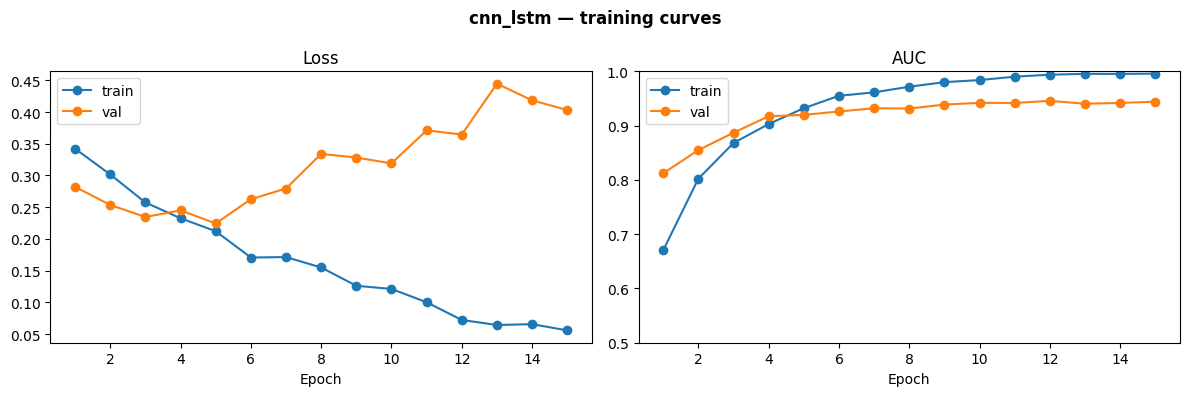

In [ ]:
# 9. Training curves
import matplotlib.pyplot as plt
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_loss, 'o-', label='train'); ax[0].plot(h.epoch, h.val_loss, 'o-', label='val')
ax[0].set(title='Loss', xlabel='Epoch'); ax[0].legend()
ax[1].plot(h.epoch, h.train_auc, 'o-', label='train'); ax[1].plot(h.epoch, h.val_auc, 'o-', label='val')
ax[1].set(title='AUC', xlabel='Epoch', ylim=(0.5, 1.0)); ax[1].legend()
plt.suptitle(f'{RUN_NAME} — training curves', fontweight='bold')
plt.tight_layout(); plt.savefig(OUT / 'training_curves.png', dpi=150); plt.show()

## Evaluation
- Load the **best** checkpoint (highest validation AUC).
- **Decision threshold** chosen on the validation set (Youden's J = max TPR − FPR), never on test.
- Test results: overall, per manipulation method, and on **FaceShifter** — a method the model never saw in training.

In [ ]:
# 10. Thresholds from validation
from sklearn.metrics import roc_curve, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, balanced_accuracy_score

model.load_state_dict(torch.load(BEST, map_location=device, weights_only=False)['model'])

def youden_threshold(labels, probs):
    fpr, tpr, thr = roc_curve(labels, probs)
    return float(np.clip(thr[np.argmax(tpr - fpr)], 1e-6, 1 - 1e-6))

val_vp, val_fp = predict(val_df)
THRESH = youden_threshold(val_df.label.values, val_vp)
FRAME_THRESH = youden_threshold(np.repeat(val_df.label.values, N_FRAMES), val_fp.ravel())
print(f'video threshold {THRESH:.3f} | frame threshold {FRAME_THRESH:.3f}')

predict:   0%|          | 0/88 [00:00<?, ?it/s]

video threshold 0.982 | frame threshold 0.987


In [ ]:
# 11. Test results
test_vp, test_fp = predict(test_df)
unseen_vp, unseen_fp = predict(unseen_df)
real_mask = test_df.label.values == 0

def metrics(name, labels, probs):
    pred = (probs >= THRESH).astype(int)
    return dict(subset=name, videos=len(labels), AUC=roc_auc_score(labels, probs), accuracy=accuracy_score(labels, pred),
                balanced_acc=balanced_accuracy_score(labels, pred), precision=precision_score(labels, pred, zero_division=0),
                recall=recall_score(labels, pred, zero_division=0), F1=f1_score(labels, pred, zero_division=0))

rows = [metrics('All test (real + 4 methods)', test_df.label.values, test_vp)]
for meth in TRAIN_METHODS:
    mask = real_mask | (test_df.method.values == meth)
    rows.append(metrics(f'Real vs {meth}', test_df.label.values[mask], test_vp[mask]))
rows.append(metrics(f'Real vs {UNSEEN_METHOD} (unseen)',
                    np.r_[test_df.label.values[real_mask], unseen_df.label.values],
                    np.r_[test_vp[real_mask], unseen_vp]))
results = pd.DataFrame(rows).round(4)
results.insert(0, 'model', RUN_NAME)
results.to_csv(OUT / 'results.csv', index=False)
results

predict:   0%|          | 0/88 [00:00<?, ?it/s]

predict:   0%|          | 0/18 [00:00<?, ?it/s]

,model,subset,videos,AUC,accuracy,balanced_acc,precision,recall,F1
0,cnn_lstm,All test (real + 4 methods),700,0.9341,0.8543,0.8420,0.9508,0.8625,0.9045
1,cnn_lstm,Real vs Deepfakes,280,0.9608,0.8750,0.8750,0.8387,0.9286,0.8814
2,cnn_lstm,Real vs Face2Face,280,0.9369,0.8464,0.8464,0.8299,0.8714,0.8502
3,cnn_lstm,Real vs FaceSwap,280,0.9372,0.8500,0.8500,0.8311,0.8786,0.8542
4,cnn_lstm,Real vs NeuralTextures,280,0.9013,0.7964,0.7964,0.8120,0.7714,0.7912
5,cnn_lstm,Real vs FaceShifter (unseen),280,0.7447,0.6393,0.6393,0.7191,0.4571,0.5590


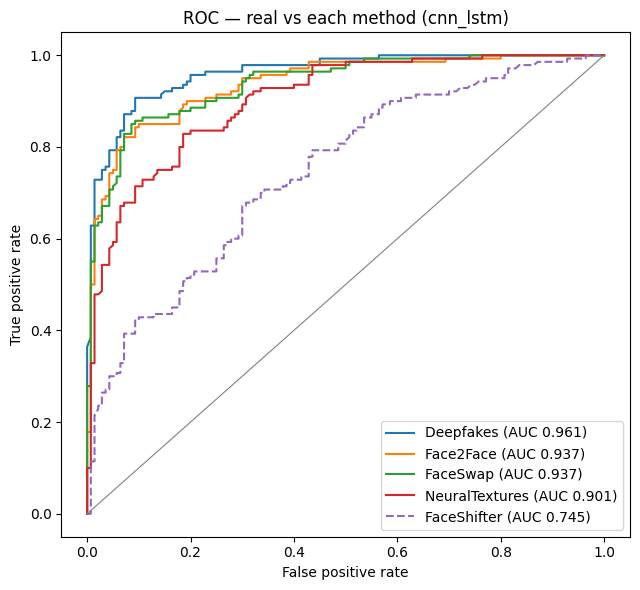

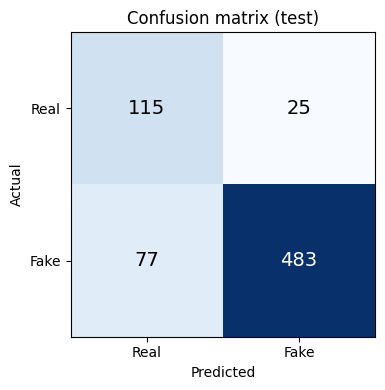

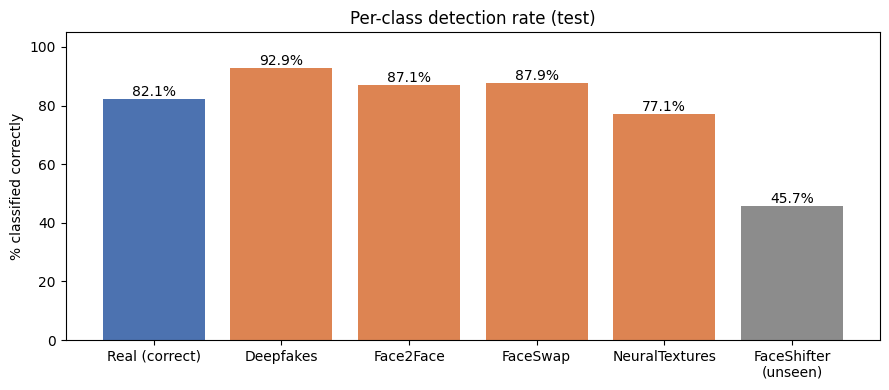

In [ ]:
# 12. Charts: ROC curves, confusion matrix, per-method detection rate
fig, ax = plt.subplots(figsize=(6.5, 6))
for meth in TRAIN_METHODS + [UNSEEN_METHOD]:
    if meth == UNSEEN_METHOD:
        l, p = np.r_[np.zeros(real_mask.sum()), np.ones(len(unseen_vp))], np.r_[test_vp[real_mask], unseen_vp]
    else:
        mask = real_mask | (test_df.method.values == meth)
        l, p = test_df.label.values[mask], test_vp[mask]
    fpr, tpr, _ = roc_curve(l, p)
    ax.plot(fpr, tpr, ls='--' if meth == UNSEEN_METHOD else '-', label=f'{meth} (AUC {roc_auc_score(l, p):.3f})')
ax.plot([0, 1], [0, 1], c='grey', lw=0.8)
ax.set(title=f'ROC — real vs each method ({RUN_NAME})', xlabel='False positive rate', ylabel='True positive rate')
ax.legend(loc='lower right'); plt.tight_layout(); plt.savefig(OUT / 'roc_curves.png', dpi=150); plt.show()

cm = confusion_matrix(test_df.label.values, (test_vp >= THRESH).astype(int))
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, str(v), ha='center', va='center', fontsize=14, color='white' if v > cm.max() / 2 else 'black')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'],
       xlabel='Predicted', ylabel='Actual', title='Confusion matrix (test)')
plt.tight_layout(); plt.savefig(OUT / 'confusion_matrix.png', dpi=150); plt.show()

rates = {'Real (correct)': (test_vp[real_mask] < THRESH).mean()}
for meth in TRAIN_METHODS:
    rates[meth] = (test_vp[test_df.method.values == meth] >= THRESH).mean()
rates[f'{UNSEEN_METHOD}\n(unseen)'] = (unseen_vp >= THRESH).mean()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(list(rates), [v * 100 for v in rates.values()], color=['#4C72B0'] + ['#DD8452'] * 4 + ['#8C8C8C'])
ax.bar_label(bars, fmt='%.1f%%'); ax.set(ylabel='% classified correctly', ylim=(0, 105), title='Per-class detection rate (test)')
plt.tight_layout(); plt.savefig(OUT / 'per_method.png', dpi=150); plt.show()

## Grad-CAM — where the model looks
For one correctly detected test video per method: the frame with the highest fake score, with the Grad-CAM map overlaid (red = strongest influence on the "fake" score).

In [ ]:
import torch, torch.nn.functional as F, deepguard

def gradcam(model, clip, frame_idx):
    model.eval()
    if model.rnn is not None:
        model.rnn.train()          # cuDNN LSTM backward needs train mode; output is identical (no dropout)
    store = {}
    def hook(_m, _i, out):
        out.retain_grad(); store['a'] = out
    h = model.features.register_forward_hook(hook)
    try:
        with torch.enable_grad():
            _, fl = model(clip.unsqueeze(0).float())
            model.zero_grad(set_to_none=True)
            fl[0, frame_idx].backward()
        act, grad = store['a'][frame_idx].detach(), store['a'].grad[frame_idx].detach()
    finally:
        h.remove(); model.eval()
    cam = F.relu((grad.mean(dim=(1, 2), keepdim=True) * act).sum(0))
    cam = cam / (cam.max() + 1e-8)
    cam = F.interpolate(cam[None, None], size=tuple(clip.shape[-2:]), mode='bilinear', align_corners=False)[0, 0]
    return cam.cpu().numpy()

deepguard.gradcam = gradcam
print('Grad-CAM patched')

Grad-CAM patched


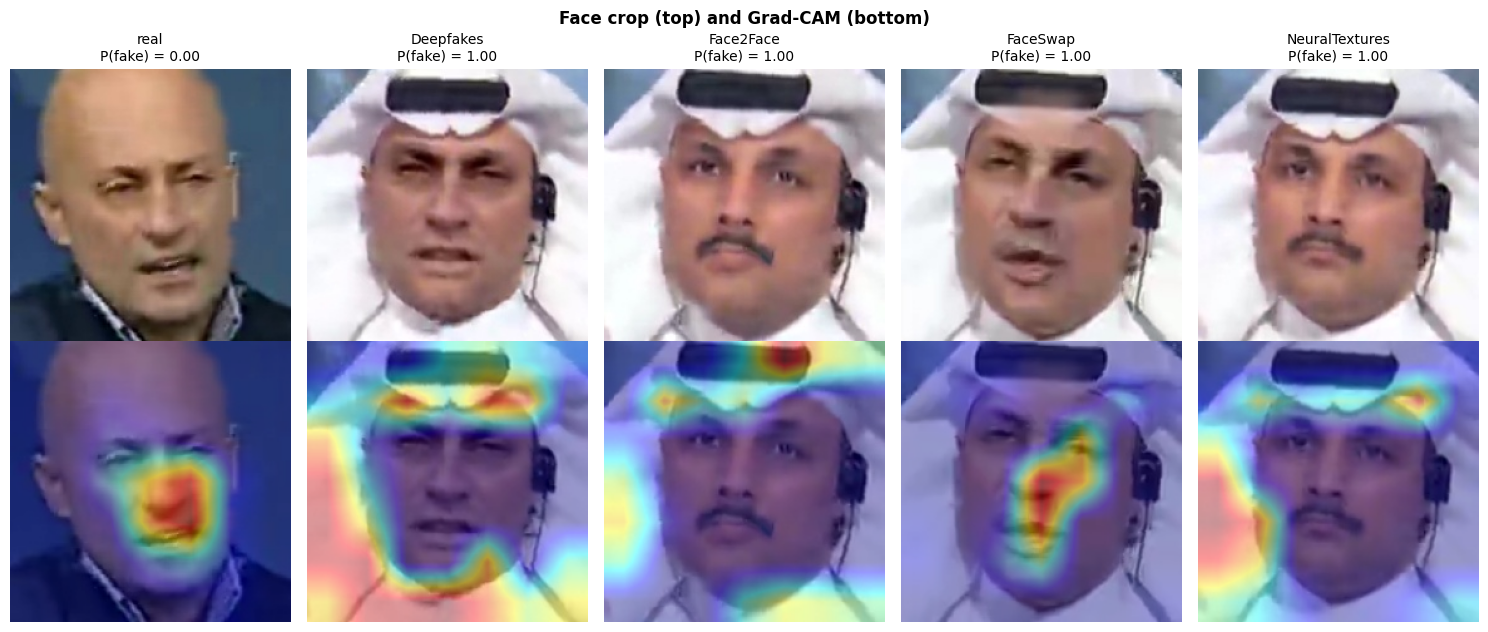

In [ ]:
# 13. Grad-CAM examples
ds = ClipDataset(test_df, train=False)
examples = []
for meth in ['real'] + TRAIN_METHODS:
    rows_m = np.where(test_df.method.values == meth)[0]
    correct = [i for i in rows_m if (test_vp[i] >= THRESH) == (meth != 'real')]
    i = (correct or list(rows_m))[0]
    crops = ds.load_raw(i, train=False)
    k = int(test_fp[i].argmax())
    cam = gradcam(model, to_tensor(crops).to(device), k)
    examples.append((meth, test_vp[i], crops[k], overlay_heatmap(crops[k], cam)))

fig, ax = plt.subplots(2, len(examples), figsize=(3 * len(examples), 6.4))
for j, (meth, p, crop, over) in enumerate(examples):
    ax[0, j].imshow(crop); ax[0, j].set_title(f'{meth}\nP(fake) = {p:.2f}', fontsize=10)
    ax[1, j].imshow(over)
    ax[0, j].axis('off'); ax[1, j].axis('off')
plt.suptitle('Face crop (top) and Grad-CAM (bottom)', fontweight='bold')
plt.tight_layout(); plt.savefig(OUT / 'gradcam_examples.png', dpi=150); plt.show()

## Export for the backend
`deepguard_v1.pt` stores the weights **and** every setting the backend needs (frames, crop size, margin, normalisation, thresholds), so nothing has to be copied by hand.

In [ ]:
# 14. Export
import shutil
all_row = results.iloc[0]
config = dict(version='deepguard-v1', run=RUN_NAME, backbone='efficientnet_b0', temporal=TEMPORAL, hidden=256,
              n_frames=N_FRAMES, crop_size=CROP_SIZE, margin=MARGIN, mean=MEAN, std=STD,
              threshold=THRESH, frame_threshold=FRAME_THRESH, face_detector='MTCNN (facenet-pytorch)',
              trained_on='FaceForensics++ C40: real + ' + ', '.join(TRAIN_METHODS),
              test_auc=float(all_row.AUC), test_accuracy=float(all_row.accuracy))
torch.save({'state_dict': model.state_dict(), 'config': config}, OUT / 'deepguard_v1.pt')
shutil.copy('deepguard.py', OUT / 'deepguard.py')
print(f"saved {OUT / 'deepguard_v1.pt'} ({(OUT / 'deepguard_v1.pt').stat().st_size / 1e6:.1f} MB)")
config

saved /content/drive/MyDrive/DeepGuard_runs/cnn_lstm/deepguard_v1.pt (28.9 MB)


{'version': 'deepguard-v1',
 'run': 'cnn_lstm',
 'backbone': 'efficientnet_b0',
 'temporal': 'lstm',
 'hidden': 256,
 'n_frames': 16,
 'crop_size': 224,
 'margin': 1.3,
 'mean': (0.485, 0.456, 0.406),
 'std': (0.229, 0.224, 0.225),
 'threshold': 0.9822195768356323,
 'frame_threshold': 0.9865716695785522,
 'face_detector': 'MTCNN (facenet-pytorch)',
 'trained_on': 'FaceForensics++ C40: real + Deepfakes, Face2Face, FaceSwap, NeuralTextures',
 'test_auc': 0.9341,
 'test_accuracy': 0.8543}

## End-to-end check (exactly what the backend will run)
Raw `.mp4` → `DeepGuardPredictor.predict_video()` → verdict, per-frame scores, suspicious segment, Grad-CAM heatmap.

real       000.mp4: FAKE  P(fake)=0.998  suspicious=0.0–15.8 s  faces 16/16


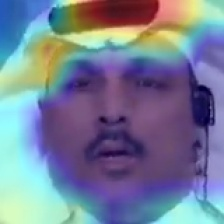

Deepfakes  000_003.mp4: FAKE  P(fake)=0.991  suspicious=5.28–7.36 s  faces 16/16


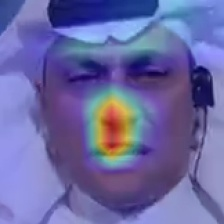

In [ ]:
# 15. End-to-end test on raw test videos
from IPython.display import Image, display
predictor = DeepGuardPredictor(OUT / 'deepguard_v1.pt')
for meth in ['real', 'Deepfakes']:
    row = test_df[test_df.method == meth].iloc[0]
    video = DRIVE_SRC / meth / f'{row.video_id}.mp4'
    heat = OUT / f'heatmap_{meth}.jpg'
    r = predictor.predict_video(video, heatmap_path=heat)
    print(f"{meth:10s} {video.name}: {r['verdict']}  P(fake)={r['fake_probability']:.3f}  "
          f"suspicious={r['suspicious_start']}–{r['suspicious_end']} s  faces {r['stats']['faces_detected']}/{r['stats']['frames_sampled']}")
    display(Image(str(heat), width=200))

In [ ]:
for vid, meth in [('000', 'real'), ('000_003', 'Deepfakes')]:
    i = test_df.index[(test_df.video_id == vid) & (test_df.method == meth)][0]
    print(f'{meth:10s} {vid}: P(fake) from saved crops = {test_vp[i]:.3f}')
print(f'threshold = {THRESH:.3f}')
print(f'real test videos wrongly flagged as fake: {(test_vp[real_mask] >= THRESH).sum()} / {real_mask.sum()}')

real       000: P(fake) from saved crops = 0.999
Deepfakes  000_003: P(fake) from saved crops = 0.999
threshold = 0.982
real test videos wrongly flagged as fake: 25 / 140
